In [2]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.cleaning import load_processed
from src.metrics import add_core_metrics, add_rolling_metrics

df = add_rolling_metrics(add_core_metrics(load_processed()))
rep = df[df["is_reported"]]
load = rep["total_system_load"].astype(float)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
print(load.rolling("7D").count().value_counts().sort_index())
print(load.rolling("14D").count().value_counts().sort_index())

total_system_load
1.0      3
2.0      4
3.0     12
4.0    123
5.0    566
6.0     12
Name: count, dtype: int64
total_system_load
1.0       1
2.0       1
3.0       1
4.0       1
5.0       6
6.0       3
7.0      22
8.0      18
9.0     243
10.0    403
11.0     21
Name: count, dtype: int64


In [6]:
by_reports = load.rolling(7, min_periods=3).mean()
print("correlation:", round(rep["load_avg_7d"].corr(by_reports), 4))
print("mean abs difference:", round((rep["load_avg_7d"] - by_reports).abs().mean(), 1))

correlation: 0.9996
mean abs difference: 55.7


In [7]:
print("raw     :", round(load.diff().std(), 1))
print("7-day   :", round(rep["load_avg_7d"].diff().std(), 1))
print("14-day  :", round(rep["load_avg_14d"].diff().std(), 1))

raw     : 140.3
7-day   : 73.2
14-day  : 68.0


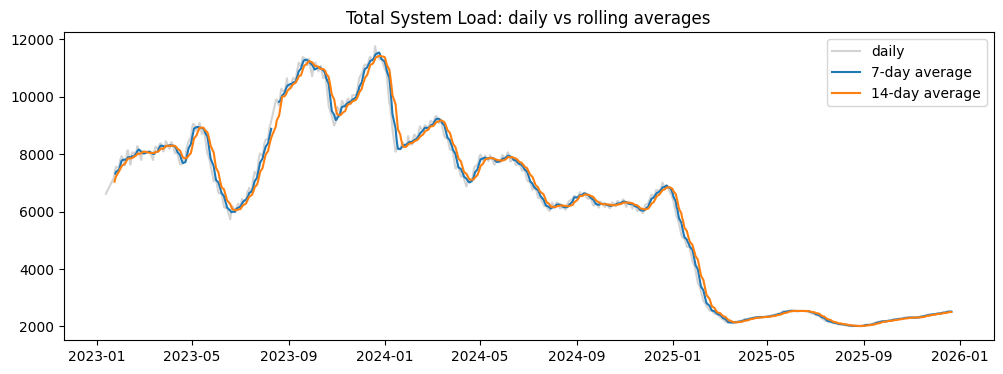

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rep.index, load, color="lightgray", label="daily")
ax.plot(rep.index, rep["load_avg_7d"], label="7-day average")
ax.plot(rep.index, rep["load_avg_14d"], label="14-day average")
ax.set_title("Total System Load: daily vs rolling averages")
ax.legend()

In [9]:
print(rep["volatility_index_14d"].describe(percentiles=[.75, .9, .95]).round(2))
print(rep["volatility_index_14d"].nlargest(5).round(2))
print(rep.groupby(rep.index.year)["volatility_index_14d"].agg(["mean", "median", "max"]).round(2))
print(rep.groupby(rep.index.to_period("Q"))["volatility_index_14d"].mean().round(2))

count    718.00
mean       2.48
std        2.05
min        0.27
50%        1.73
75%        3.06
90%        5.13
95%        6.64
max       13.14
Name: volatility_index_14d, dtype: float64
date
2025-02-10    13.14
2025-02-11    13.02
2025-02-09    12.47
2025-02-04    12.10
2025-02-12    11.98
Name: volatility_index_14d, dtype: float64
      mean  median    max
date                     
2023  2.92    2.47   7.26
2024  2.23    1.71  10.45
2025  2.33    1.13  13.14
date
2023Q1    2.27
2023Q2    3.54
2023Q3    3.17
2023Q4    2.51
2024Q1    3.00
2024Q2    2.24
2024Q3    2.04
2024Q4    1.61
2025Q1    5.79
2025Q2    0.99
2025Q3    1.43
2025Q4    0.83
Freq: Q-DEC, Name: volatility_index_14d, dtype: float64


<Axes: title={'center': 'Care Load Volatility Index (14-day, %)'}, xlabel='date'>

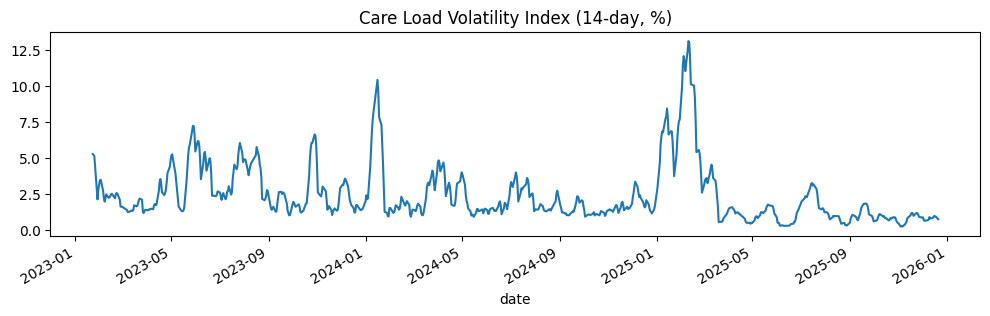

In [10]:
rep["volatility_index_14d"].plot(figsize=(12, 3), title="Care Load Volatility Index (14-day, %)")

In [11]:
rep.groupby(rep.index.year)["total_system_load"].apply(
    lambda s: s.astype(float).std() / s.astype(float).mean() * 100).round(1)

date
2023    18.1
2024    15.0
2025    33.3
Name: total_system_load, dtype: float64